In [1]:
import sys
sys.path.append('/home/pavel/pyadi-iio/')
sys.path.append('/home/pavel/libiio')
import adi
import matplotlib.pyplot as plt
import numpy as np

In [3]:
# Create radio
sdr = adi.ad9363("ip:192.168.2.2")
samp_rate = 30.72e6

'''Configure Rx properties'''
sdr.rx_enabled_channels = [0, 1]
sdr.sample_rate = int(samp_rate)
sdr.rx_rf_bandwidth = int(30.72e6)
sdr.rx_lo = int(2.19e9)
sdr.rx_buffer_size = 35000
sdr.gain_control_mode_chan0 = "manual"
sdr.gain_control_mode_chan1 = "manual"
sdr.rx_hardwaregain_chan0 = int(40)
sdr.rx_hardwaregain_chan1 = int(40)

In [4]:
sig = sdr.rx()

In [5]:
sig = np.asarray(sig)

In [9]:
sig = sig[...,:8000]

/home/pavel/miniconda3/lib/python3.13/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/pavel/miniconda3/lib/python3.13/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


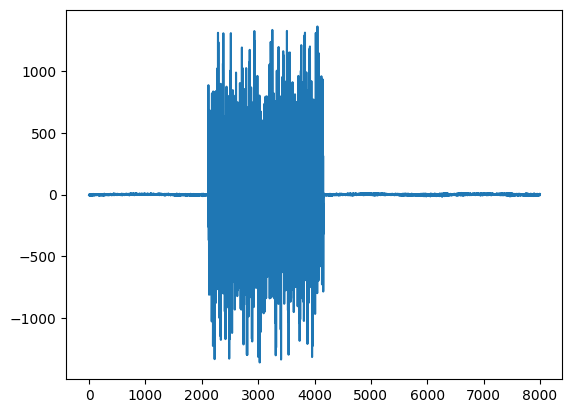

In [10]:
plt.plot(sig[0])
plt.show()

In [10]:
spec = np.fft.fft(sig[0])

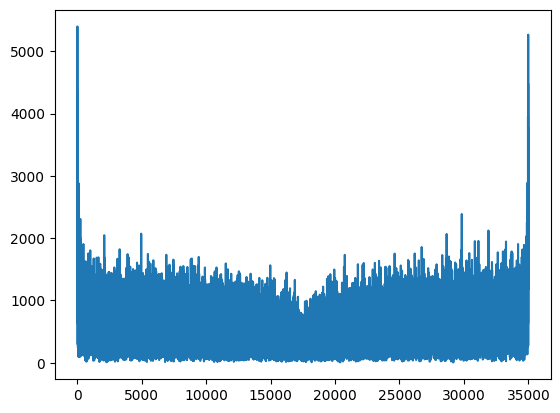

In [11]:
plt.plot(np.abs(spec))
plt.show()